# INSTRUCTOR EDITION — Hammett Neural Networks: Detailed Worked Solutions

**Purpose:** A reproducible solution with first-principles derivations, numerical answers, diagnostic plots, and scientific limitations. The 30-molecule development set is used for fitting and validation; 120 supplied labeled examples are reserved for final evaluation. The reference test labels are used only for evaluation, not candidate selection.

## Roadmap and grading

| Student task | Required evidence | Points |
|---|---|---:|
| 1. Chemical data and feature interpretation | Identify variables; inspect 30/120 split; explain descriptor approximation | 15 |
| 2. Neural-network mathematics | Worked forward pass; dimensions and bias/activation explanations | 20 |
| 3. Training and learning curves | Training/validation plots; epoch and overfitting interpretation | 20 |
| 4. Evaluation and baseline | Test MAE/RMSE/R², parity plot, linear baseline and interpretation | 20 |
| 5. Model sensitivity and screening | Three seeds, rankings, uncertainty discussion | 15 |
| 6. Extract scoring function and reflect | Verify manual forward pass; propose new chemical application | 10 |
| **Total** | | **100** |

**Grading principles:** roughly half the marks reward scientific reasoning and reproducibility rather than simply obtaining a small numerical error. Every graph needs labeled axes and units. State the seed and split used. There is no required target accuracy, because a small dataset produces seed-dependent results.

## Part 1. The chemistry and the dataset

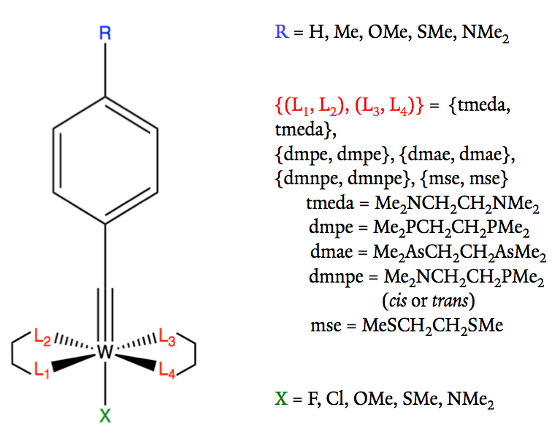

The original case study varies the **R** substituent, ligand environment **L**, and **X** substituent around tungsten. Its library contains 150 candidate complexes, with 30 selected for model development and 120 reserved as a test set. The original assignment uses *Hammett-style substituent constants* as a compact numerical description of electronic substituent effects. In organic aromatic chemistry, σ values summarize how substituents influence a reference reaction; extending them to donor ligands in tungsten complexes is a chemical **approximation**, not an exact physical identity.

A row in the CSV represents **one candidate molecule**. The thirteen columns contain:

- column 0: a three-digit molecular code (**identifier**, never an input feature);
- columns 1–10: **ten input features** (five pairs of meta/para Hammett-style constants for R, L1, L2, L3, and X);
- columns 11–12: two predicted **targets** for learning: DFT-derived $d_{xy}$-related orbital energy and $d_{xy}$–LUMO gap (in eV, as represented in the original assignment).

A **feature** is information supplied to the model; a **target** is the numerical answer it tries to learn. **Regression** means predicting continuous values (such as eV), not predicting chemical class labels. A molecular ID is useful for looking up molecules but has no numerical physical meaning.

### Worked example: features are not labels

For a hypothetical row `[111, 0.0, 0.0, ..., 0.34, 0.06, -2.52, 2.47]`, `111` identifies the complex; ten intervening numbers describe it; the last two are the labels we wish to predict. Learning from the ID would encode arbitrary bookkeeping rather than chemistry.

**Why reserve test molecules?** A student preparing for an exam should practice with examples *not* identical to the exam questions. A model likewise needs new molecules to check whether it has learned transferable relationships instead of memorizing the 30 training examples. Here the 120 held-out labels are available for the course exercise, but they must never be used to choose model settings.

In [1]:
# 1. Load all three supplied datasets without Google Drive paths.
# If original CSV files are next to this notebook, use them directly.
# Otherwise the compressed originals embedded below make this notebook self-contained.
import io, gzip, base64, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EMBEDDED = {'HammettNNTrain.csv': 'H4sIABHU5GoC/42VC5KjMAxET6CbEMr6Wfb9L7Yt2ITPYCeTGkIFqyW/ljAzLwWfV1lF8xoyvC+rGi6lLi9ZXRZZrbp0YpFNo6yc//p4o7HsUpYCumqxMGLV/6G7xu2L9wJieenaHVEmwUho9k7YsiAd3XnuzFIGCU0aErr/2e/fcvE717w2zdTWsNdmGkhdeRw/gIXcFQK99dJJ9j2V2JLEr+Df9AA+oKXG1kj2FR+tqQEXlgYgXqCAIq8Kzz5sIBGniGPkDhLze+6JFzeg0aEjoR08nIc8HvvooJoNUWpzJ6nyXWRAVPMW9ga7kd5Q/WTOsRzGdGjV6AYtsfPDuTlvwGkMAlVJ1a/hD87csLa0R/HHhAa5JZ9OyocqpjOHpVp4J3UZ0ZiOOCYmDS4eNUirfhUZ8USTZMMpoeU+lH7zZFuKacnJE4YhZOLvBxMvbkh7FiAlDDUoH/GPY3Lqzd3IXrmSmZzyzm04XpIoWfr2xpMiZK5P+/8255ZVFCnMZNWmCk/4shWBL7ipk7Nf4fzgw2U9hoPzzOjZny58eTo/O05c8+yICOzIVW4Sz6YcXdk5X3teQslN7/nnR8mJassaaisCKG5DKLM5tzwPOg4j8urfFYZMNRVhMeM4/QcQ/hkyywcAAA==', 'HammettNNTest.csv': 'H4sIABHU5GoC/52Zz24cNwzGn2DfwUCuzkL8K+leoJcUBQoUyDWHoKcWQdBD8/b9yNnxzoyzHskI4own5m9FiuJHyh+e6Pr0x6fPlw9PjIe/v/77BY+Cx29fvsejXp8+0e21xfPtveOZb+9rPN/eNzzL7X2P5+U9levT5+U14RM/397iM3/578fT13++fv/rB76X/P7jpz9/+/3p1y/f1v8g4ueCPx/LlSW+Vn74XK5Sn5fv+epFiz/zVYo1BUYmMLS8qMFRqQ0YdWsMjM5gLH6Ur+bkBAbVbg0MG2bgK3l8bemT1qIGEJuSXIgpQfiZ+Cs/fRAs+IpAfNRr0abPAk9aeMJybnyPg1y740PTXKnDXAfM03+YdqEKU/LqsLQzy53XMGcO41YNnyurz8w/+efFW1hZqWEnja3Cjt+0W/MGUSoZJZZWwkzfMntx0DoescZSJNZoj40OvrVGvYWl1lilvuxoC0fkwdN2U6tHaNVMkVrKY/Z3d7kgsAFAasNehux3eWE97TnDrDYAOMaAuHqGXBtdyOjV8XgzseVq7BH9wrXiVBiP2a8xgD0WH2e81cpIUJMhwDYIaosLhZhxtkzHCLf0MUKu4fOrdKzf31j/g2qHLI90DxcYf8CQUcbWC4TRorz0ml64DkNujoiyRc2tcChWYWOAQz5gGzmWUXtsBxPFf8G7+LE6KgRrdqBoNuuxKEUFq8DJO3A7QcCJSUXorB08fQ9vVQauKEwo6EiZYNk066gQokg+AOE0nOV97IaVIjbyORKzJ4UnKJtKquw9KrB5h3Os45S7cixFnLoCYKOAY4HpzVoWGEOBYDkG5VRKRFqEQwVbD3sesr8fzl47RyC4CRvsZcR+V2N5VW5DHMTO7Y8R0J5RJEgo66ukGBYbJEQsxEpxnEzlOdA9NajWLukRKiZAMgXahQb6niCqCK3qHCjTDH611i17BXdQjB8ewzMloeh0UEGZGiJtMgXaKQq7hK4WrQ1H0HSOdDs/qFEc9aU2QnvAZhOUQwqpQVQgMIgUXdjpnPSgIiPMIkVSsK0ES2ZZO9GSTim9BTkAmE7DVvGibPSriSK33eY4Rw3DEdHU43BRiHarnpYw1K0OmqOAKGj8Dtp9MjLJndTKHSydZ63qpWjsY8IyhB4kmyUdtEu65+HREp2+8C5mw9JFRWJMca8UEB6HbJSLoyHMOicNEBmG7EoTSc2lWGmID9sg5dWIgIEtixMVbL4cwnIqXtQka3bj2G/hEfONdnmeLhVGR4eDO2C9jUHrVTKSTiKw1xH7VfzRTKZs58AqetzKYbHR7GXQTRooMkPZb2crnoHMpFCdAq1KE3NaxFO5gmHjjENWVF8kSwu6q4vYwwJzMjstVwoIctEGr0xmODvBKrEINBnQK8TZdAq06pW7R9nsRRXxMRuHHOWKY5aJiayj6xc/j89DueK+yBVhgkAOO8+iNmMaotRSrGpBkFwnUWucuBULXW9eI05uU5yjVhF5Ni3SC1900Sobv3O765ShCVukhTCFKvEkaaNRnVOkJDpW3eTI/LimvlzgVTUBymZQx+nKakYK7U/1i/JLpMav4NSiE1dsHALEPAbYKJPhiIQYYAogAGQIsL+vIc6KXlnCBx0jrDXZ+zJKOAbXi8rGgVMlaZheotJY3C6oyInpYQBKKVDpFW6Lntmuy5VlYKES1yIq9qbdUXgt4kTmKLCq270en5dy0ahpCoKMEvbbxZ4DDqEFBESHIavi9CUEUpoZADYGOMYiNg5agSDaT+vD2RUdLTJTpMYpNB5mbIYr9pp3XD36KTUdZbzcsxWRvGczLoil2RjgqCwuPWsvOirkor8djjeGIC9R4XqrFdnhPIPZKErjEr9baHlfrS4TmN0YhTqZV3+k4ZQNY14NPto1J87W5GLL5d39B2YVRbznnld0sQYcvwd3l5Uov+EmznStwMk7cFtx4VYlNhFNFHLBlrvAWd46TbF7XHsq0pQvxntXxwQi+/XsUp3Q7RrLOGTXtpvVOK4V3RwoOkFZK2+etajYhE7Xlru7EcSrXw5gckjFRAG7mNCBczb+NI/ERjw6arCJjJjvIqEx/sUQ1zE+megQ4BaE1mrz5V6pY0vFzo2PbX7tqfdohxUEPbo/KEUvcxyqbw0Oz3E2DUiLG2+ASkc4VKc4L8mRAy3igS7K1CYYx/CQcGYZ2sWL2eNiczYFFc9dRqtvyDLjOdD9+Clp/j6OkKkBkinQNvEw7xZ6vhXUi5lNkA5REq/ZdRI6P9RkHwjT42EIzXhGCkECiqdR91hxzVGYStzUmMssahstgjRE3JmLo+65TsPWyYq5pSxD2P8HG5UIFyIhAAA=', 'HammettNN150.csv': 'H4sIABHU5GoC/51aTW8cNwz9BfsfDOTqLCR+SvcCvaQoUKBArjkEPbUIgh6af99Hzo53Zpz1SIaRjXa8fCs9UeQj5Q9P9fr0x6fPlw9PhMHfX//9giFj+O3L9xjK9elTvT3WGN+eG8Z0e+4xvj1vGPPteY/x8ryW69Pn5XHFN36+PcV3/vLfj6ev/3z9/tcPvOd8//HTn7/9/vTrl2/rL2qtzwU/H8uVOF6dHo7LlQUvxZ4/0lWp4h1dxZQ6YGgGxp+X93S1IsCjKxdtAhiegKnLAw8cYW/LbBoBRmZgND6KFVm1CozqXRswdBgDr9XiteWaxIsogEil8qXSwjA+E//4p4MXYuVapMkzYyUtVkI0YLzSCWOrtcOaizjoJD63vrPI126Ycn65VGwqyYB5sgfTztVhWs0NlnpmueMM5lgojJsrvpdXxpbVH/574QpWWjzsuJE67OhNuw1NJTkmbiXM+C2zHT8C9wp+yIMfljcNV2a0Y4jFlcJhpI+NDqS0VnsLS/FYnrw4UgsG+MFo60tusSeiKvBooTH7O09UsCMBgBMFex6y3xGmPe0p90dkDCCJkyuOYAlrForYIDpgfWSwklvutLR6qfo62L15GhlhzmLvCrnjKCuN2a8Mwh5Lj8DU3AnnQnkIYEuh6LKEgliAgKAyhnBzPq1wcXy/c4/564DxgUJx67kChFi4r71B4YNkgR1Ug/PQtbdeAoOGMe5Mchz2mAfhBxg8irElE7upEZq7J5kmwyA3PuGLGvnKwWvMQscADpzCmyim4T28gpCD8SusLj7m87lYmvaYlCB+O+DoPXD3nKwI4ZGSpSJq0LKSSbRdakYQydzcSTrw5D14a44mR5BHasU5CCydxjrmahYNGUOgENTRfieGc3a4xXOctp4oNIGyyUpClslbrWNxxOMo+yTFPZK4wkGJZALkJZUvWbV2AYCOAhxDb2/aMvQqQifxkdnT3M7cglNh+A/sacj+Hi+6dwo2qTEp7HnEfscjrUJMwQPLkP1KIYO8zNzI3TDWc+MjfdJzCyoEEckrtxxWALpMREsxRBqhOaC7c1b3zkkHEhGAeApoxysvGsqqY19E5oBu2qC01jWVn1mg6ATKgWn4CQcUQkscO30cjE+0gvQmoVcKPAZzUpoD2oiGGloaWYpqixnxFNBOPJBxTkm8wQ9V5pBu3ozITRF1vWVGUJ1AOaoJtRACsXv1QjbA9WNRwVw4tZmWwKJprI24sHCnkGk1DrvxLNZOZCD+pmIr8HGAyTTYKjZqFrWuLDi7pnM4R82BECCpn4IurnU362nJgaDegWaIrgI0egfaRnFweoU4dWDxPNZWbyBtlKjjzbvE1OQdcDe5IahqQwkpdhJIOot0EBvcLc+1lChzmXZbMKw1auFI72ZRgzLROMhGalCUJZkWuAGEh0F2kbyy51QgNcAPyTjKS57MXABTZgDoIMCrOtlay2RQC3acD7yeKo3aOHNko/A/phHzjdCwPO3CBMHFzAPWWxJbd86tsBocsIzYr/ShGEmNlc0iZj21PTKXXoBJM0KCHP1xWGRQ5AT4gaRfC03hbDSGpIhGUaRA4RmUvVu2Yrmf6dwiU0CrwIieSWyrkANDxzGO8sIWpSIFsv7C+jDunqmL7Cpir4s0rEppCufurrDOHl9RN6xMeQZnpy1KLAYaFdIC+6UyBbRKCzOLrNSLSMxGx0GOyoI0nbDUjiKY7Zznh8qC+qIsKgpqHEmjWaiNsABLLbWAF5BkPAm10xUxpZiPzILcyKZWNHRcMw+yTadwjnqiVkuRyr3QRRY9oe+6SkAhsKT/Sg1INIm00RGdUkhwVE2ycbT5poXYcqHgogwomYR6uVMo3rNfATECGJ2BObYq4sAGFkSEXYReCB+/WRCNolKw/+CZaAxgoxoUxzXTNU4+AHgIYN8PrpTJ0oljDTKGsKY760tVbM5wOdIB6+M9Q20pWai4YF95Q+KpTLj1VULFYe5MZ6YbidCa5oWDRttRmE9MD22IzPH4dgfpLGe2xxZEiX6psL5pd9QFGrtU1ZCyRLaeNt54yEkjusPvhYYRth2HpYEDR40AIzyKsXe4KAzjBgP1CkBkGGTVAX2hkUsU9SI6BnDkMzYfGRwboT8NlGfXEHVJ/oU9wpHSMMamq0Dm2UDvodZFeRRjl/TzojWK7lLhjSrDIOuFRGHOCwmlgg1RHQM4JnvjnpkMmh3TsLc5faOFYGW5l3CHmxrNwGySfKOsOFveJ4rxBMwuwSPr5OVElViUzMCsLQNaUryjpoG7mg5jvGoXSJfs+bTGF12uKO4fmM3xbD2db5mXVnoP3D3RRyYLqhCg3AHH74DbpntqzuEI0NjwJ13uKGbx1qYBmUUvSeDqBCydxjq2DXD4l+udKNOU9lsxlv0jEi5VkbvXQKEJlF2xmyhWUaMp8TjIruZV9QhnjtoBKDKBsma3DCORFSvqMyUdhXh1QYyyOzURAvxF+cjtmShoFmcWfESvSZmGzDd0lih/EBW1OE4Z84j9jkmJ5k20YJAsASBDADcSW/NmSxO9w1NZz42Pxa33VIQo3gQI8so1x+TCSxMF2c0Dh+ZwNhK1xQUjgEoHHcJTOD9zUWslPF1kDml10+xLgVkodhWdwDgSXZnS31HhXFQfR+OzLkKx9BeUuAp/V5oD2rQRquTfllScmQDiKaAt0yyRPW8ZB0gyh7Qmvt7y79F6r9BpqjqBcuCazbNOqqhVcChtgOzHrQSJPy+KxSn82mga6s44eTakaom+rxrPQm05r8jAsXuQ1ga2TKbB1pYCUUsFFVcdajqHcyC+5gJL5SL/A7EuiJY+KQAA'}
def read_hammett(filename):
    path = pathlib.Path(filename)
    if path.exists():
        raw = path.read_bytes()
        return np.loadtxt(io.BytesIO(raw.replace(b'\r\n', b'\n').replace(b'\r', b'\n')), delimiter=',', comments='#')
    raw = gzip.decompress(base64.b64decode(EMBEDDED[filename]))
    # Original CSV files use old Macintosh CR-only line endings. Normalize them.
    raw = raw.replace(b'\r\n', b'\n').replace(b'\r', b'\n')
    return np.loadtxt(io.BytesIO(raw), delimiter=',', comments='#')

train_raw = read_hammett('HammettNNTrain.csv')
test_raw = read_hammett('HammettNNTest.csv')
full_raw = read_hammett('HammettNN150.csv')
feature_names = ['R_meta','R_para','L1_meta','L1_para','L2_meta','L2_para',
                 'L3_meta','L3_para','X_meta','X_para']
print('Training:', train_raw.shape, 'Test:', test_raw.shape, 'Full library:', full_raw.shape)
assert train_raw.shape == (30,13) and test_raw.shape == (120,13)
assert set(train_raw[:,0].astype(int)).isdisjoint(set(test_raw[:,0].astype(int)))
assert set(full_raw[:,0].astype(int)) == set(np.r_[train_raw[:,0],test_raw[:,0]].astype(int))

def make_frame(raw):
    return pd.DataFrame(raw, columns=['molecule_id']+feature_names+['dxy_eV','gap_eV'])
display(make_frame(train_raw).head())


Training: (30, 13) Test: (120, 13) Full library: (150, 13)


,molecule_id,R_meta,R_para,L1_meta,L1_para,L2_meta,L2_para,L3_meta,L3_para,X_meta,X_para,dxy_eV,gap_eV
0,111.0,0.0,0.0,-0.23,-0.72,-0.23,-0.72,-0.23,-0.72,0.34,0.06,-2.52,2.46529
1,122.0,0.0,0.0,0.10,0.13,0.10,0.13,0.10,0.13,0.37,0.23,-4.06,3.30474
2,133.0,0.0,0.0,0.22,0.00,0.22,0.00,0.22,0.00,0.12,-0.27,-3.95,3.42719
3,144.0,0.0,0.0,0.18,0.03,0.18,0.03,0.18,0.03,0.15,0.00,-4.12,3.34284
4,155.0,0.0,0.0,-0.23,-0.72,0.10,0.13,0.10,0.13,-0.16,-0.83,-3.48,2.84379


### Student task 1 — chemical interpretation (15 points)

**1A (5 pt):** For molecule 111, list its ten input features and both target values. Explain why its identifier must not be used as a feature.

**1B (5 pt):** Explain, in your own words, what meta and para Hammett constants describe. Why should approximations for donor ligands be treated cautiously?

**1C (5 pt):** Explain why the 30-molecule training set should cover diverse R/L/X combinations. Describe one possible failure mode if it does not.

**Your response (write below):**

> 1A: ...  
> 1B: ...  
> 1C: ...

### Instructor solution — Task 1 (15/15)

**1A.** The next executed cell prints the *actual* molecule-111 row directly from the supplied dataset; the two last entries are the reference `dxy_eV` and `gap_eV` targets, not inputs. The identifier is an arbitrary database label, not a chemical descriptor. Including it could make the network learn accidental ordering of rows rather than molecular trends.

**1B.** Hammett constants quantify electronic substituent effects relative to hydrogen in a reference aromatic reaction series. The meta and para values describe substituents at different ring positions and can reflect different balances of inductive and resonance effects. Applying analogous constants to coordinating donor ligands is a useful encoding hypothesis, not proof that a ligand's metal coordination or steric influence is captured by a benzene substituent constant.

**1C.** Covering diverse R, ligand and X choices helps the model encounter a range of electronic environments. If, for example, all highly donating ligands occur only with one X group in training, the network may falsely attribute the ligand effect to X and extrapolate poorly to new combinations.

In [2]:
# Instructor answer 1A: extract the row rather than guessing chemical feature values.
row111=make_frame(full_raw).loc[lambda d:d.molecule_id==111]
assert len(row111)==1
print('Molecule 111: ten input descriptors and two targets')
display(row111.T.rename(columns={row111.index[0]:'value'}))

Molecule 111: ten input descriptors and two targets


,value
molecule_id,111.00000
R_meta,0.00000
R_para,0.00000
L1_meta,-0.23000
L1_para,-0.72000
L2_meta,-0.23000
L2_para,-0.72000
L3_meta,-0.23000
L3_para,-0.72000
X_meta,0.34000


### Detailed numerical solution: one molecule and its feature vector
A row of the original CSV has 13 columns: **molecule ID**, **10 input descriptors**, **two reference orbital-energy targets**. The ID is not a physical predictor: giving it to a model would risk teaching it an arbitrary ordering. For molecule 111, the printed table above gives the ten actual descriptors and two labels. The 10 descriptors can be represented as a column vector

$$\mathbf{x}_{111}=(x_1,x_2,\ldots,x_{10})^{\mathsf T}.$$

A 30-row feature matrix therefore has shape $30\times10$; the two-target label matrix has shape $30\times2$. These are distinct because the model learns a relationship *from* descriptor values *to* computed orbital properties.

**Conceptual answers:** Different para substituents alter electron donation/withdrawal, changing tungsten–benzylidyne electronic structure. Identical descriptors for two molecules would make them indistinguishable to this model even if their actual energies differ. A learned relationship is not a mechanistic proof of causality.

In [3]:
print('Exact input descriptors for molecule 111:', np.array2string(row111.iloc[0,1:11].to_numpy(dtype=float),precision=5))
print('Reference orbital energies for molecule 111 (eV):',row111.iloc[0,11:13].to_numpy(dtype=float))
print('Shapes (30 molecules):', train_raw[:,1:11].shape,train_raw[:,11:13].shape)
assert train_raw[:,1:11].shape==(30,10)


Exact input descriptors for molecule 111: [ 0.    0.   -0.23 -0.72 -0.23 -0.72 -0.23 -0.72  0.34  0.06]
Reference orbital energies for molecule 111 (eV): [-2.52134  2.46529]
Shapes (30 molecules): (30, 10) (30, 2)


## Part 2. From one neuron to a neural network

Start with the equation for a straight line: $y=wx+b$. Here $w$ is the **weight** $slope$ and $b$ is the **bias** $intercept$. A single neuron generalizes this to several inputs:

$$z=w_1x_1+\cdots+w_{10}x_{10}+b, \qquad a=f(z).$$

The sum $z$ is an intermediate weighted score; an **activation function** $f$ lets the model represent nonlinear interactions. Without nonlinear activations, stacking linear layers is equivalent to a single linear transformation.

**Example:** if $x=(2,-1)$, $w=(0.5,0.25)$, and $b=0.1$, then $z=2(0.5)+(-1)(0.25)+0.1=0.85$. The ReLU activation gives $\max(0,z)=0.85$. If the bias were zero, the result would be 0.75.

We will use the **same 10 → 12 → 8 → 2 architecture** as the original assignment:

- 10 inputs: substituent descriptors;
- first hidden layer: 12 tanh neurons; $\tanh(z)$ lies between −1 and 1;
- second hidden layer: 8 ReLU neurons; $\mathrm{ReLU}(z)=\max(0,z)$;
- 2 linear outputs: continuous orbital-energy targets.

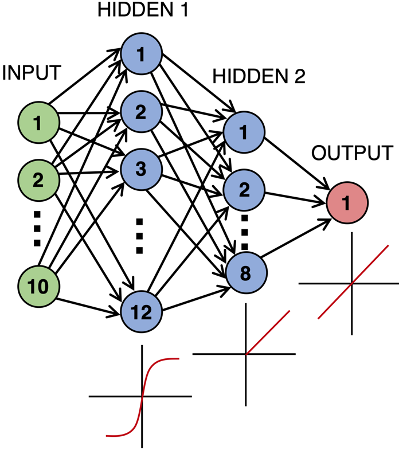

Using column vectors, the full forward pass is

$$\mathbf h_1=\tanh(W_1\mathbf x+\mathbf b_1), \quad
\mathbf h_2=\mathrm{ReLU}(W_2\mathbf h_1+\mathbf b_2),\quad
\hat{\mathbf y}=W_3\mathbf h_2+\mathbf b_3.$$

The dimensions are $W_1:12\times10$, $b_1:12$, $W_2:8\times12$, $b_2:8$, $W_3:2\times8$, $b_3:2$. The model therefore has $120+12+96+8+16+2=254$ trainable parameters. This is large relative to only 30 labeled molecules: regularization and restraint in interpreting predictions matter.

In [4]:
# A two-feature neuron calculated by hand and by NumPy
x_demo = np.array([2.0,-1.0]); w_demo = np.array([0.5,0.25]); b_demo = 0.1
z_demo = np.dot(w_demo,x_demo)+b_demo
print('Weighted sum:',z_demo,'ReLU output:',max(0,z_demo))
assert np.isclose(z_demo,0.85)

# A tiny 2x2 layer illustrates matrix multiplication: two neurons at once.
W_demo = np.array([[0.5,0.25],[-0.2,0.8]])
b_demo_vector = np.array([0.1,-0.1])
print('Two-neuron weighted sums:',W_demo @ x_demo + b_demo_vector)


Weighted sum: 0.85 ReLU output: 0.85
Two-neuron weighted sums: [ 0.85 -1.3 ]


### Student task 2 — neural-network math (20 points)

**2A (7 pt):** Compute $z$ for a neuron with $x=(1,2)$, $w=(0.3,-0.4)$, and $b=0.2$. Give both tanh and ReLU outputs (numerically, to three decimals).

**2B (5 pt):** Explain what changes when a bias is added and why nonlinear activations matter.

**2C (5 pt):** Identify all six weight/bias array shapes for the 10–12–8–2 model. Reproduce the total parameter count.

**2D (3 pt):** Explain why a two-output neural network is appropriate for simultaneously learning the orbital energy and the energy gap.

**Your response:**

> 2A: ...  
> 2B: ...  
> 2C: ...  
> 2D: ...

### Instructor solution — Task 2 (20/20)

**2A.** The preactivation is $z=0.3(1)-0.4(2)+0.2=-0.300$. Thus $\tanh(z)\approx-0.291$ and $\mathrm{ReLU}(z)=\max(0,z)=0$.

**2B.** A bias shifts the neuron's response even when the inputs vanish; without biases, each linear transformation must map the zero vector to zero. Nonlinear activations allow a network to represent curved, piecewise, and interacting input-output relationships; stacking linear layers alone is equivalent to one linear layer.

**2C.** For column-vector notation: $W^{(1)}\colon(12,10)$, $b^{(1)}\colon(12,)$; $W^{(2)}\colon(8,12)$, $b^{(2)}\colon(8,)$; $W^{(3)}\colon(2,8)$, $b^{(3)}\colon(2,)$. The number of trainable parameters is $120+12+96+8+16+2=254$. PyTorch stores linear weights in these output-by-input shapes.

**2D.** Both quantities depend on the same molecular descriptors, so shared hidden layers can learn common chemistry and output two separate values. This can help when targets share underlying patterns, although it does not guarantee better predictive accuracy.

### Complete numerical derivation of the neuron calculation
A neuron first forms the **preactivation** (weighted sum plus bias):

$$ z = \sum_{j=1}^d w_j x_j+b. $$

With $\mathbf{x}=(1,2)$, $\mathbf{w}=(0.3,-0.4)$, and $b=0.2$,

$$z=(0.3)(1)+(-0.4)(2)+0.2=0.3-0.8+0.2=-0.3.$$

Its tanh output is $\tanh(-0.3)=\frac{e^{-0.3}-e^{0.3}}{e^{-0.3}+e^{0.3}}\approx-0.29131$, while ReLU returns $\max(0,-0.3)=0$. The **bias** plays the same conceptual role as a y-intercept. Without nonlinear activation, multiple stacked affine layers can be collapsed into one affine map: $W_2(W_1x+b_1)+b_2=(W_2W_1)x+(W_2b_1+b_2)$.

**Architecture:** For one input $x\in\mathbb{R}^{10}$, hidden layer 1 has 12 neurons, hidden layer 2 has 8, and the output has 2. The trainable parameter count is:

$$ (10\cdot12+12)+(12\cdot8+8)+(8\cdot2+2)=132+104+18=\boxed{254}. $$

Two outputs allow joint modeling of the orbital energy and the energy gap, but sharing hidden layers is a modeling hypothesis, not proof of a causal relationship.

In [5]:
z_hand=0.3*1+(-0.4)*2+0.2
print(f'Weighted sum z={z_hand:.6f}; tanh={np.tanh(z_hand):.6f}; ReLU={max(0,z_hand):.6f}')
print('Parameter count:',(10*12+12)+(12*8+8)+(8*2+2))


Weighted sum z=-0.300000; tanh=-0.291313; ReLU=0.000000
Parameter count: 254


## Part 3. Preparing trustworthy train/validation/test data

The original files contain a **30-molecule labeled training set** and **120 held-out molecules**. We further split the 30 into a small training portion and a **validation** portion. Validation allows us to choose stopping time or hyperparameters without inspecting the final test set.

**Standardization:** a feature measured on a much larger numerical scale can dominate early optimization. For each feature $j$, transform $x'_j=(x_j-\mu_j)/s_j$, where the mean and standard deviation are calculated *using the training subset only*. Apply the same $\mu_j,s_j$ to validation and test; do not refit them on test molecules.

Because there are only 30 labeled examples, any single validation split is noisy. We will fix a seed to make the exercise reproducible and discuss sensitivity later. Here we predict two outputs in their original units but optionally scale their training targets to stabilize learning; the inverse transform is needed to report energies in eV.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X30=train_raw[:,1:11]; y30=train_raw[:,11:13]
X_test_raw=test_raw[:,1:11]; y_test=test_raw[:,11:13] # FOR FINAL EVALUATION ONLY
ids_test=test_raw[:,0].astype(int)
ix_fit,ix_val=train_test_split(np.arange(len(X30)),test_size=0.2,random_state=42)
X_fit_raw,X_val_raw=X30[ix_fit],X30[ix_val]
y_fit_raw,y_val_raw=y30[ix_fit],y30[ix_val]
x_scaler=StandardScaler().fit(X_fit_raw)
y_scaler=StandardScaler().fit(y_fit_raw)
X_fit=x_scaler.transform(X_fit_raw).astype('float32')
X_val=x_scaler.transform(X_val_raw).astype('float32')
y_fit=y_scaler.transform(y_fit_raw).astype('float32')
y_val=y_scaler.transform(y_val_raw).astype('float32')
X_test=x_scaler.transform(X_test_raw).astype('float32')
print('Development training examples:',len(X_fit),'Validation examples:',len(X_val))
print('First standardized feature mean (training):',X_fit[:,0].mean().round(4))


Development training examples: 24 Validation examples: 6
First standardized feature mean (training): 0.0


### Numerical worked example of standardization and leakage prevention
For descriptor $j$, fit-set-only standardization uses

$$\mu_j=\frac{1}{n_{\rm fit}}\sum_i x_{ij},\quad s_j=\sqrt{\frac{1}{n_{\rm fit}}\sum_i(x_{ij}-\mu_j)^2},\quad x'_{ij}=\frac{x_{ij}-\mu_j}{s_j}.$$

`StandardScaler` uses the population standard deviation. For intuition, consider a feature with fit values $2,4,6$: $\mu=4$, $s=\sqrt{8/3}=1.63299$, and the transformed values are $(-1.22474,0,1.22474)$. The validation and test values must be transformed with **these same fitted parameters**, rather than refitting on unseen data. Targets are likewise standardized *for training* and converted back to eV before scientific evaluation.

**Small-sample warning:** With only 24 molecules in the fitting subset and 6 for validation, tuning choices are noisy. All selected hyperparameters and stopping epochs are based on validation, while the final test labels are assessed only after model development.

In [7]:
from sklearn.preprocessing import StandardScaler
s_demo=StandardScaler().fit(np.array([[2.],[4.],[6.]]))
print('Worked standardization:',s_demo.mean_[0],s_demo.scale_[0],s_demo.transform([[2],[4],[6]]).ravel())
print('Real fit descriptor 1: mean',x_scaler.mean_[0],'scale',x_scaler.scale_[0]);print('Real target means (eV):',y_scaler.mean_)


Worked standardization: 4.0 1.632993161855452 [-1.22474487  0.          1.22474487]
Real fit descriptor 1: mean 0.006249999999999996 scale 0.11488445282108455
Real target means (eV): [-3.47038708  3.06861083]


## Part 4. Training: predictions, loss, gradients and epochs

A neural network begins with randomly initialized weights. For each training molecule, it computes a prediction by passing its descriptors through each layer (**forward pass**). We compare predicted and reference energies with **mean squared error (MSE)**:

$$\mathrm{MSE}=\frac{1}{2N}\sum_{i=1}^N\sum_{k=1}^{2}(\hat y_{ik}-y_{ik})^2.$$

Here the factor 2 in the denominator counts the two output quantities; MSE gives larger penalties to larger errors. **Backpropagation** computes how changing each parameter would change the loss using the chain rule from calculus. An **optimizer** (Adam here) updates weights to reduce the loss. An **epoch** is one pass through the training examples; a **batch** is the smaller subset used for one update. An excessive number of epochs can **overfit** the training examples: training loss falls while validation loss rises.

PyTorch is used below instead of the original older Keras script, keeping its architecture and Adam optimizer while making the training mechanics explicit. We train on scaled targets for numerical convenience but report results in eV.

Selected epoch (minimum validation loss): 301


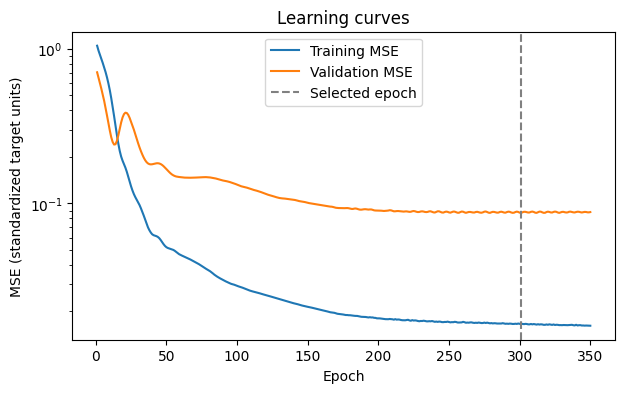

In [8]:
import torch
from torch import nn

torch.set_num_threads(1)
def make_model(seed=42):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(10,12),nn.Tanh(),nn.Linear(12,8),nn.ReLU(),nn.Linear(8,2))

def train_network(seed=42,epochs=350,learning_rate=0.01,weight_decay=0.01):
    net=make_model(seed)
    optimizer=torch.optim.Adam(net.parameters(),lr=learning_rate,weight_decay=weight_decay)
    loss_function=nn.MSELoss()
    xx=torch.tensor(X_fit); yy=torch.tensor(y_fit)
    xv=torch.tensor(X_val); yv=torch.tensor(y_val)
    history={'epoch':[],'train_loss':[],'val_loss':[]}
    best_val=float('inf'); best_state=None; best_epoch=0
    for epoch in range(1,epochs+1):
        net.train(); optimizer.zero_grad()
        loss=loss_function(net(xx),yy)
        loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            vloss=loss_function(net(xv),yv).item()
        history['epoch'].append(epoch)
        history['train_loss'].append(loss.item())
        history['val_loss'].append(vloss)
        if vloss < best_val:
            best_val=vloss;best_epoch=epoch
            best_state={k:v.detach().clone() for k,v in net.state_dict().items()}
    net.load_state_dict(best_state)
    return net,pd.DataFrame(history),best_epoch

model,history,best_epoch=train_network()
print('Selected epoch (minimum validation loss):',best_epoch)
plt.figure(figsize=(7,4));plt.plot(history.epoch,history.train_loss,label='Training MSE')
plt.plot(history.epoch,history.val_loss,label='Validation MSE')
plt.axvline(best_epoch,color='gray',linestyle='--',label='Selected epoch')
plt.xlabel('Epoch');plt.ylabel('MSE (standardized target units)');plt.yscale('log')
plt.legend();plt.title('Learning curves');plt.show()


### Mathematical explanation of the training loop
For $N$ molecules and $K=2$ predicted targets, a standardized mean-squared-error objective is

$$L(\theta)=\frac1{NK}\sum_{i=1}^{N}\sum_{k=1}^{K}[\hat y_{ik}'(\theta)-y_{ik}']^2.$$

For a single prediction $\hat y$, the derivative is $\partial (\hat y-y)^2/\partial\hat y=2(\hat y-y)$. Backpropagation applies the chain rule through the linear layers and nonlinear activations. A basic gradient-descent update is $\theta\leftarrow\theta-\eta\nabla_\theta L$; Adam adapts the steps using running estimates of gradient moments. Weight decay penalizes large parameters and can improve generalization. One epoch in this implementation evaluates all 24 fit examples once, using one full-batch optimizer step.

A decreasing training loss alone does **not** establish generalization. If validation loss rises after a minimum, the network may be overfitting. The code restores weights from the minimum-validation-loss epoch.

In [9]:
# Differentiate an elementary squared-error loss by hand and with PyTorch.
w_ex=torch.tensor(2.0,requires_grad=True);x_ex=torch.tensor(3.0);y_ex=torch.tensor(4.0)
l_ex=(w_ex*x_ex-y_ex)**2;l_ex.backward()
print('Example loss = (2*3-4)^2 =',float(l_ex),'and dL/dw = 2*(6-4)*3 =',float(w_ex.grad))


Example loss = (2*3-4)^2 = 4.0 and dL/dw = 2*(6-4)*3 = 12.0


/tmp/ipykernel_1046/2888889172.py:4: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print('Example loss = (2*3-4)^2 =',float(l_ex),'and dL/dw = 2*(6-4)*3 =',float(w_ex.grad))


### Student task 3 — learning curves (20 points)

**3A (5 pt):** Define epoch, batch, loss function and optimizer in your own words.

**3B (7 pt):** Include a labeled learning-curve plot. Report the epoch selected by minimum validation error. Describe evidence for or against overfitting.

**3C (8 pt):** Experiment with a second learning rate (e.g., `learning_rate=0.001`) while keeping the split fixed. Plot or compare the curves and explain which learning rate learns faster and whether the final validation loss changes. **Do not use test results to choose the learning rate.**

**Your response:**

> 3A: ...  
> 3B: ...  
> 3C: ...

### Instructor solution — Task 3 (20/20)

**3A.** An *epoch* is one complete pass over the fit subset. A *batch* is the group of examples used for one gradient update; the supplied trainer uses a full batch of 24 fit molecules per epoch. A *loss function* measures discrepancies between predictions and labels (here mean squared error on standardized targets). An *optimizer* updates weights to reduce loss (here Adam).

**3B.** The baseline cell plots training and validation MSE and marks the epoch with minimum validation MSE. The selected epoch is computed rather than hard-coded below. Evidence for overfitting is a persistent decline in training error while validation error rises; a small temporary fluctuation is not conclusive.

**3C.** The next cell compares learning rates 0.01 and 0.001 on the same split, using minimum validation losses and selected epochs. Typically the larger step size improves faster early on, but the actual winner must be established from validation curves, not assumed. Test labels must not be used for learning-rate selection.

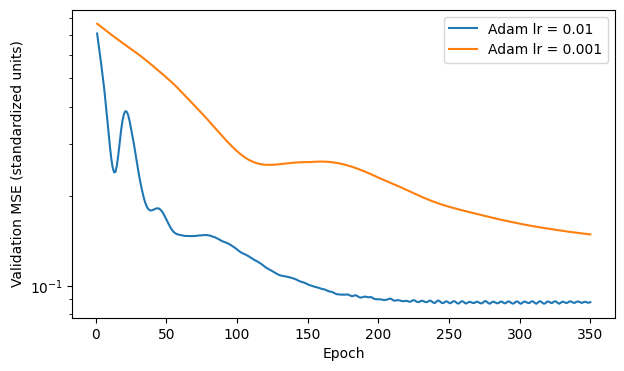

Selected epochs: 301 350


In [10]:
# Guided experiment (students can change the learning rate).
model_slow,history_slow,selected_slow=train_network(learning_rate=0.001)
plt.figure(figsize=(7,4))
plt.plot(history.epoch,history.val_loss,label='Adam lr = 0.01')
plt.plot(history_slow.epoch,history_slow.val_loss,label='Adam lr = 0.001')
plt.xlabel('Epoch');plt.ylabel('Validation MSE (standardized units)')
plt.yscale('log');plt.legend();plt.show()
print('Selected epochs:',best_epoch,selected_slow)


In [11]:
# Instructor answer 3B–3C: numerical learning-rate comparison on validation only.
summary_lr=pd.DataFrame([
  {'learning_rate':0.01,'best_epoch':best_epoch,'min_validation_MSE':history.val_loss.min(),'final_training_MSE':history.train_loss.iloc[-1]},
  {'learning_rate':0.001,'best_epoch':selected_slow,'min_validation_MSE':history_slow.val_loss.min(),'final_training_MSE':history_slow.train_loss.iloc[-1]}
])
display(summary_lr.round(5))
print('Lower minimum validation MSE at learning rate:',summary_lr.loc[summary_lr.min_validation_MSE.idxmin(),'learning_rate'])

,learning_rate,best_epoch,min_validation_MSE,final_training_MSE
0,0.010,301,0.08688,0.01616
1,0.001,350,0.14875,0.04217


Lower minimum validation MSE at learning rate: 0.01


### Instructor interpretation: learning-rate study
The summary immediately above reports the **actual best validation MSE** and corresponding epoch for each learning rate. This is a comparison of training behavior on a fixed, very small split; it is **not** a repeated-cross-validation estimate of expected performance. The learning-rate choice should be explained by the table's minimum validation MSE, not by which curve decreases fastest initially. If results are close, state that the comparison is inconclusive instead of claiming a decisive improvement.

## Part 5. Evaluation on unseen molecules

**MAE** is the average magnitude of prediction errors: $\mathrm{MAE}=\langle|\hat y-y|\rangle$. **RMSE** is the square root of average squared errors and weights large mistakes more strongly. **R²** compares residual errors with a mean-prediction reference; values can be negative. In a **parity plot**, each point compares a prediction with its computed reference; perfect predictions lie along $y=x$.

A neural network should be compared to a **simple baseline**. Linear regression uses $\hat{y}=\beta_0+\sum_j\beta_jx_j$ and cannot naturally learn arbitrary nonlinear feature interactions. With only 24 fitting examples, a neural network is not guaranteed to beat it. We use Ridge regression (a regularized linear baseline) and train it on the *same* development subset.

**Methodology warning:** a lower test error does not automatically mean the network has learned causal chemistry; dataset design, descriptor coverage and closely related molecules also matter.

,model,target,MAE_eV,RMSE_eV,R2
0,Neural network,dxy_eV,0.0486,0.0593,0.9881
1,Neural network,gap_eV,0.0931,0.1129,0.9183
2,Ridge baseline,dxy_eV,0.0423,0.0542,0.9901
3,Ridge baseline,gap_eV,0.0885,0.1039,0.9309


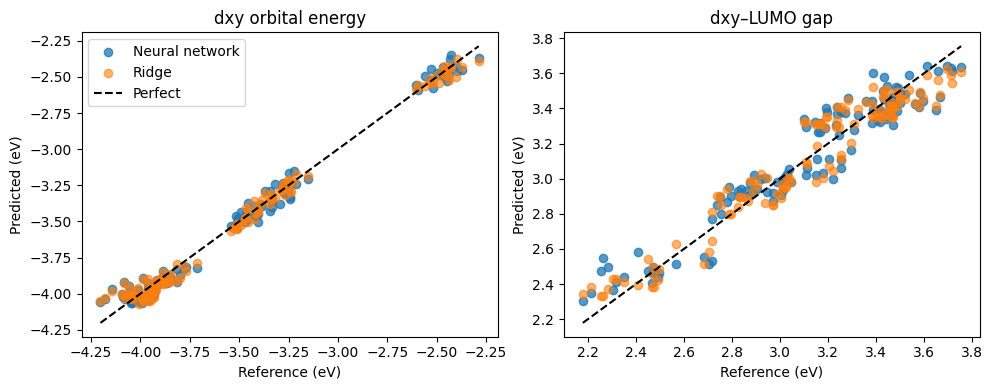

In [12]:
from sklearn.linear_model import Ridge

def predict_ev(net,X):
    net.eval()
    with torch.no_grad():
        ys=net(torch.tensor(X,dtype=torch.float32)).numpy()
    return y_scaler.inverse_transform(ys)

# The following cell is the one-time held-out assessment of the predefined models.
net_pred=predict_ev(model,X_test)
ridge=Ridge(alpha=1.0).fit(X_fit,y_fit_raw)
ridge_pred=ridge.predict(X_test)

def metrics_frame(y,models):
    rows=[]
    for name,preds in models.items():
        for j,target in enumerate(['dxy_eV','gap_eV']):
            rows.append({'model':name,'target':target,
                         'MAE_eV':mean_absolute_error(y[:,j],preds[:,j]),
                         'RMSE_eV':np.sqrt(mean_squared_error(y[:,j],preds[:,j])),
                         'R2':r2_score(y[:,j],preds[:,j])})
    return pd.DataFrame(rows)
results=metrics_frame(y_test,{'Neural network':net_pred,'Ridge baseline':ridge_pred})
display(results.round(4))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for j,ax in enumerate(axes):
    ax.scatter(y_test[:,j],net_pred[:,j],alpha=0.75,label='Neural network')
    ax.scatter(y_test[:,j],ridge_pred[:,j],alpha=0.6,label='Ridge')
    low=min(y_test[:,j].min(),net_pred[:,j].min(),ridge_pred[:,j].min())
    high=max(y_test[:,j].max(),net_pred[:,j].max(),ridge_pred[:,j].max())
    ax.plot([low,high],[low,high],'k--',label='Perfect')
    ax.set(xlabel='Reference (eV)',ylabel='Predicted (eV)',title=['dxy orbital energy','dxy–LUMO gap'][j])
axes[0].legend();plt.tight_layout();plt.show()


In [13]:
# Instructor answer 4A–4B: largest prediction errors and per-target comparison.
for j,label in enumerate(['dxy_eV','gap_eV']):
    err=np.abs(net_pred[:,j]-y_test[:,j])
    worst=np.argsort(-err)[:5]
    print('Target:',label,'— five largest NN absolute test errors')
    display(pd.DataFrame({'molecule_id':ids_test[worst],'reference_eV':y_test[worst,j],
                          'NN_pred_eV':net_pred[worst,j],'absolute_error_eV':err[worst]}).round(4))
for target in ['dxy_eV','gap_eV']:
    r=results.loc[results.target==target].sort_values('MAE_eV')
    print(f'{target}: lower test MAE = {r.iloc[0]["model"]} ({r.iloc[0]["MAE_eV"]:.4f} eV)')

Target: dxy_eV — five largest NN absolute test errors


,molecule_id,reference_eV,NN_pred_eV,absolute_error_eV
0,342,-4.1450,-3.9684,0.1766
1,542,-4.0821,-3.9181,0.1640
2,142,-4.2019,-4.0579,0.1440
3,242,-4.1779,-4.0353,0.1426
4,545,-3.7133,-3.8228,0.1095


Target: gap_eV — five largest NN absolute test errors


,molecule_id,reference_eV,NN_pred_eV,absolute_error_eV
0,415,2.2618,2.5462,0.2844
1,323,3.6509,3.3918,0.2591
2,134,3.1004,3.3398,0.2394
3,563,3.2206,2.9966,0.2241
4,115,2.2541,2.4752,0.2211


dxy_eV: lower test MAE = Ridge baseline (0.0423 eV)
gap_eV: lower test MAE = Ridge baseline (0.0885 eV)


### Worked error calculations and how to read the tables
For each reference value $y_i$ and prediction $\hat y_i$, the residual is $r_i=\hat y_i-y_i$ and its absolute value is $|r_i|$. The metrics are

$$\mathrm{MAE}=\frac1N\sum_i|r_i|,\qquad \mathrm{RMSE}=\sqrt{\frac1N\sum_i r_i^2},\qquad R^2=1-\frac{\sum_i r_i^2}{\sum_i(y_i-\bar y)^2}.$$

For residuals $(-0.2,0.1,0.3)$ eV, $\mathrm{MAE}=0.2$ eV and $\mathrm{RMSE}=\sqrt{(0.04+0.01+0.09)/3}\approx0.2160$ eV. RMSE emphasizes large errors. A negative $R^2$ means a model predicts worse than the constant mean of the evaluated references. For the model comparison, use the actual metric table printed above; a neural network does not necessarily beat Ridge when there are only 24 fitting examples.

In [14]:
demo_resid=np.array([-0.2,0.1,0.3]);print('Worked MAE:',np.abs(demo_resid).mean(),'RMSE:',np.sqrt(np.mean(demo_resid**2)))
print('Result table (all values evaluated on supplied 120-molecule held-out set):');display(results.round(5))


Worked MAE: 0.20000000000000004 RMSE: 0.21602468994692867
Result table (all values evaluated on supplied 120-molecule held-out set):


,model,target,MAE_eV,RMSE_eV,R2
0,Neural network,dxy_eV,0.04860,0.05935,0.98812
1,Neural network,gap_eV,0.09310,0.11291,0.91831
2,Ridge baseline,dxy_eV,0.04233,0.05420,0.99009
3,Ridge baseline,gap_eV,0.08848,0.10387,0.93086


### Student task 4 — evaluate and compare (20 points)

**4A (8 pt):** Submit the metric table and parity plots for both outputs (axes in eV). Which errors are largest?

**4B (7 pt):** Compare the neural network with Ridge for each output. Did extra model complexity help on this split? Why might either model perform better?

**4C (5 pt):** Explain why it is inappropriate to search hyperparameters repeatedly on the 120 labeled test molecules. Distinguish validation error from test error.

**Your response:**

> 4A: ...  
> 4B: ...  
> 4C: ...

### Instructor solution — Task 4 (20/20)

**4A.** The executed evaluation cell gives the two-target metric table and parity plots. MAE and RMSE have eV units; $R^2$ is dimensionless. RMSE is more sensitive to outlying errors than MAE. The accompanying solution cell explicitly finds the largest absolute errors for each target.

**4B.** Compare the per-target test MAEs in the generated table. A flexible neural network can capture nonlinear effects, but with only 24 fit molecules its variance may be high. Ridge regression is a strong low-variance baseline and can outperform a neural network on small datasets. Differences on one split do not establish universal superiority.

**4C.** Validation data support hyperparameter decisions such as epochs and learning rate. The held-out test labels estimate generalization after those choices are fixed. Repeatedly tuning against the test set leaks information, producing an optimistically biased performance estimate. With such a small dataset, further work should include repeated or nested resampling on the 30 labeled development molecules.

## Part 6. Repeated models and molecular screening

The original assignment averaged predictions across 30 independently initialized neural networks. This is an **ensemble**: random initial weights can produce slightly different fits. A mean prediction may be more stable than one fit. The standard deviation across runs is **not** a calibrated predictive confidence interval; models trained on almost identical data can agree and all be wrong. Here use three seeds as a short, classroom-friendly demonstration; increasing to 30 is optional.

**Important:** Averaging predictions $\frac1M\sum_m f_m(x)$ is not equivalent to averaging parameter tensors and then computing $f_{\mathrm{mean}\,\theta}(x)$ for nonlinear networks.

,molecule_id,predicted_dxy_eV,run_sd_eV
99,514,-2.4031,0.0508
98,513,-2.4152,0.0467
27,215,-2.4231,0.0401
25,213,-2.4493,0.0236
26,214,-2.4509,0.0155
3,115,-2.4577,0.0296
97,512,-2.4671,0.0289
96,511,-2.4676,0.0322
2,114,-2.4753,0.0247
1,113,-2.4795,0.0156


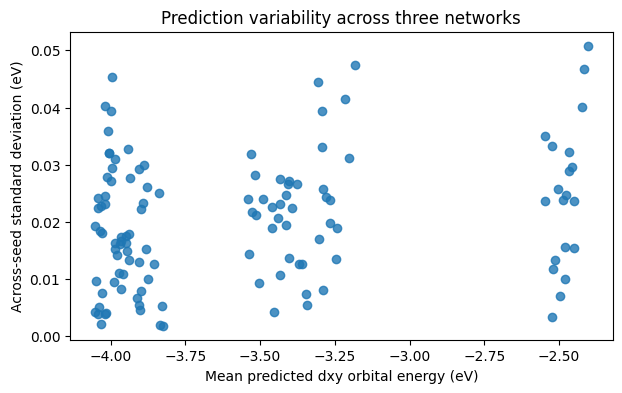

In [15]:
seed_values=[3,17,42]  # Increase to 30 seeds for a more extensive run.
ensemble=[]
for seed in seed_values:
    net,_,selected=train_network(seed=seed)
    ensemble.append(predict_ev(net,X_test))
ensemble=np.stack(ensemble)
mean_pred=ensemble.mean(axis=0)
sd_pred=ensemble.std(axis=0,ddof=1)
ranking=pd.DataFrame({'molecule_id':ids_test,'predicted_dxy_eV':mean_pred[:,0],
                      'run_sd_eV':sd_pred[:,0]})
ranking=ranking.sort_values('predicted_dxy_eV',ascending=False)
display(ranking.head(10).round(4))
plt.figure(figsize=(7,4));plt.scatter(mean_pred[:,0],sd_pred[:,0],alpha=0.8)
plt.xlabel('Mean predicted dxy orbital energy (eV)')
plt.ylabel('Across-seed standard deviation (eV)')
plt.title('Prediction variability across three networks');plt.show()


In [16]:
# Instructor answer 5A: ranking by predicted energy, not by known test labels.
display(ranking[['molecule_id','predicted_dxy_eV','run_sd_eV']].head(5).round(4))

,molecule_id,predicted_dxy_eV,run_sd_eV
99,514,-2.4031,0.0508
98,513,-2.4152,0.0467
27,215,-2.4231,0.0401
25,213,-2.4493,0.0236
26,214,-2.4509,0.0155


### Interpreting the five highest-ranked predictions
The table above selects the five largest **predicted** values of the \(d_{xy}\) orbital energy. “Highest scoring” here therefore means *highest predicted orbital energy*; it is not automatically the most active, safest, or most synthesizable compound. The reported across-seed standard deviation is the spread across independently fitted networks; it is **not** calibrated predictive uncertainty or a chemical measurement error. Out-of-domain descriptor combinations can still yield confidently wrong predictions.

For a prospective screen, rank without inspecting the supplied reference labels, verify candidate structures/feasibility, and calculate a consistent higher-quality reference for diverse shortlisted candidates.

In [17]:
top_five=ranking[['molecule_id','predicted_dxy_eV','run_sd_eV']].head(5).copy()
top_five.insert(0,'rank',np.arange(1,6));print('Requested top-five candidate ranking:');display(top_five.round(5))


Requested top-five candidate ranking:


,rank,molecule_id,predicted_dxy_eV,run_sd_eV
99,1,514,-2.40306,0.05081
98,2,513,-2.41521,0.04673
27,3,215,-2.42312,0.04006
25,4,213,-2.44934,0.02359
26,5,214,-2.45088,0.01549


### Student task 5 — sensitivity and screening (15 points)

**5A (5 pt):** Provide a table with the top five candidate IDs ranked by *predicted* \(d_{xy}\) energy and their across-seed SD.

**5B (5 pt):** Explain what a high across-seed SD might suggest and why a low SD does not prove accuracy.

**5C (5 pt):** Propose a reasonable computational follow-up strategy for choosing candidates from the high-ranking group for additional DFT verification. Discuss chemical feasibility and model extrapolation.

**Your response:**

> 5A: ...  
> 5B: ...  
> 5C: ...

### Instructor solution — Task 5 (15/15)

**5A.** The ranking is calculated from ensemble *predicted* $d_{xy}$ energies, not reference test values. The next solution cell shows the requested five IDs and their across-seed SDs.

**5B.** A large SD means that predictions are sensitive to the random initialization/training trajectory, suggesting instability. Low SD only shows agreement among these three models. Models can agree and be wrong because of a shared descriptor limitation, systematic bias, out-of-domain inputs, or insufficient training data. Three seeds are an illustrative ensemble rather than a calibrated confidence interval.

**5C.** Before new DFT calculations, inspect whether top-ranked chemical combinations are stable and synthetically accessible; assess descriptor distance from the 30 training molecules; select several high-ranked candidates, some diverse high-ranked candidates, and comparison controls; perform consistent DFT calculations on their structures and compare both targets. Avoid using already-known test references to refine the ranking under the guise of blind screening.

## Part 7. Extracting a physical scoring function from a trained network

The network is an explicit mathematical function, not a black box in the sense that its predictions cannot be reproduced. Each `nn.Linear` layer stores a weight matrix and bias vector. PyTorch uses the `output = input @ weight.T + bias` convention when inputs are batches of row vectors. In the column-vector equations above, the weight arrays already have the desired dimensions.

**Important scaling detail:** Our model uses standardized descriptors and targets. To calculate a new molecule’s orbital energies manually, first standardize its ten descriptors using the training-set means/SD, perform the three matrix operations, then inverse-transform the two predicted standardized targets to eV.

![Neural network equation](attachment:equation.png)

In [18]:
# Verify the forward-pass calculation against the network output, in eV.
net=model
layers=[layer for layer in net if isinstance(layer,nn.Linear)]
assert [(l.out_features,l.in_features) for l in layers]==[(12,10),(8,12),(2,8)]
W1,b1=[p.detach().numpy() for p in (layers[0].weight,layers[0].bias)]
W2,b2=[p.detach().numpy() for p in (layers[1].weight,layers[1].bias)]
W3,b3=[p.detach().numpy() for p in (layers[2].weight,layers[2].bias)]
x0=X_test[0]
h1=np.tanh(W1@x0+b1)
h2=np.maximum(0,W2@h1+b2)
manual_scaled=W3@h2+b3
manual_ev=y_scaler.inverse_transform(manual_scaled.reshape(1,-1))[0]
model_ev=predict_ev(net,X_test[:1])[0]
print('Manual output (eV):',manual_ev,'Network output (eV):',model_ev)
np.testing.assert_allclose(manual_ev,model_ev,rtol=1e-5,atol=1e-5)
print('All dimensions:',W1.shape,b1.shape,W2.shape,b2.shape,W3.shape,b3.shape)


Manual output (eV): [-2.559209   2.3677275] Network output (eV): [-2.559209   2.3677275]
All dimensions: (12, 10) (12,) (8, 12) (8,) (2, 8) (2,)


### Layer-by-layer manual forward-pass verification
For a single ten-descriptor molecule, after standardization, calculate the following with **column vectors**:

$$ z_1=W_1x+b_1\quad (12,),\quad h_1=\tanh(z_1)\quad (12,), $$
$$ z_2=W_2h_1+b_2\quad (8,),\quad h_2=\max(0,z_2)\quad (8,), $$
$$ s=W_3h_2+b_3\quad (2,),\quad \hat{y}_k=\mu_{y,k}+s_k\,\sigma_{y,k}.$$

The output is two predicted energy values in **electronvolts**, after inverting the target standardization. Matrices have shapes $W_1:(12,10)$, $W_2:(8,12)$, $W_3:(2,8)$. The verification below prints each intermediate vector and compares NumPy with PyTorch. The intermediate hidden values are dimensionless learned coordinates, not independently validated molecular observables.

In [19]:
z1=W1@x0+b1;z2=W2@np.tanh(z1)+b2;s_manual=W3@np.maximum(z2,0)+b3
print('Molecule ID:',int(ids_test[0]));print('Standardized x:',np.round(x0,5))
print('z1, first 12:',np.round(z1,5));print('tanh(z1):',np.round(np.tanh(z1),5))
print('z2:',np.round(z2,5));print('ReLU(z2):',np.round(np.maximum(z2,0),5))
print('Standardized outputs:',np.round(s_manual,6))
print('Prediction after inverse scaling (eV):',np.round(manual_ev,6))
print('PyTorch minus manual (eV):',np.round(model_ev-manual_ev,9))
assert np.max(np.abs(model_ev-manual_ev))<1e-4


Molecule ID: 112
Standardized x: [-0.0544   0.7793  -0.90333 -0.91483 -1.86434 -1.92722 -1.37273 -1.40305
  0.98532  0.98312]
z1, first 12: [-1.15659 -0.25502  0.36602 -0.94806 -0.88307 -0.58187  0.93956  0.87329
 -0.07973 -0.88369  0.40262  0.52137]
tanh(z1): [-0.81992 -0.24963  0.35051 -0.7389  -0.70795 -0.52403  0.73502  0.70304
 -0.07957 -0.70826  0.38219  0.47876]
z2: [ 1.41226  0.96684  0.37215 -0.85648  0.76459 -0.61463  1.43158 -0.15585]
ReLU(z2): [1.41226 0.96684 0.37215 0.      0.76459 0.      1.43158 0.     ]
Standardized outputs: [ 1.566802 -1.766081]
Prediction after inverse scaling (eV): [-2.559209  2.367728]
PyTorch minus manual (eV): [0. 0.]


### Student task 6 — interpretation and transfer (10 points)

**6A (5 pt):** Explain the manual forward-pass calculation above, including where tanh, ReLU, the biases, and inverse target scaling occur. Why do the manual and PyTorch predictions agree? Why must weight arrays from independently trained networks **not** simply be averaged as if they were predictions?

**6B (5 pt):** Propose a new chemical regression problem: name an input representation, the target property and its units, where labels would come from, and an appropriate validation strategy.

**Your response:**

> 6A: ...  
> 6B: ...

### Instructor solution — Task 6 (10/10)

**6A.** Begin with the 10-dimensional input after fit-set feature scaling, compute $h_1=\tanh(W_1x+b_1)$, then $h_2=\max(0,W_2h_1+b_2)$, then the two standardized outputs $s=W_3h_2+b_3$, and finally invert the target scaling $y=s\odot	ext{scale}_y+	ext{mean}_y$. The NumPy and PyTorch values agree because they evaluate the same trained parameters and mathematical operations (up to floating-point roundoff). Do not average independently fitted weight matrices: hidden-unit permutations and other parameter symmetries mean that corresponding array entries need not represent the same learned feature. Averaging **predictions** avoids this misalignment.

**6B.** Example: predict the vertical excitation energy $eV$ of organic chromophores using molecular fingerprints together with quantum-chemical or geometry-based descriptors. Obtain labels from a consistent TD-DFT protocol, distinguish vertical excitation energy from measured absorption maxima, split by scaffold rather than random molecule where possible, fit preprocessing only on training data, and evaluate once on a held-out scaffold test set. Compare to a simple descriptor-only baseline and report errors in eV.

### Scientific conclusions and limitations — expanded answer key

1. **What is learned?** A nonlinear mapping from ten substituent descriptors to two quantum-chemically calculated electronic observables for a particular family of tungsten complexes. It is a surrogate model for the supplied calculations, not a full electronic-structure method.
2. **Why a Ridge baseline?** Ridge estimates a linear descriptor-to-energy map, with an \(L_2\) penalty on coefficients. It is lower capacity and more interpretable than a 254-parameter network; with very few fit examples it may be more robust.
3. **What is independent?** The training/validation procedure is performed on the 30-molecule development set. The 120-molecule set is used once for final comparison, not to tune training settings. If reporting results from multiple notebook revisions informed by these test results, this is no longer a pristine external benchmark.
4. **What is the key source of uncertainty?** Only 30 development examples, correlated substituent descriptors, uncertainty of electronic-structure reference labels, and possible feature-space extrapolation; ensemble disagreement measures only one component.
5. **Are rankings experimentally established?** No. A rank based on predicted orbital energy is a screening hypothesis; validation requires independent calculations and, when relevant, synthesis and measurements.
6. **What would improve the study?** Acquire more chemically diverse training molecules, use repeated or scaffold/substituent-aware validation, tune a baseline and the NN on equivalent folds, perform learning curves versus dataset size, compare DFT protocols and report genuine prospective external validation.

**Assignment transfer example:** For chromophore excitation energies, use matched geometry/QM descriptors and consistent calculated vertical excitations as labels. Experimental absorption maxima are different physical observables and should not silently be substituted for vertical excitation energies.

## Final submission checklist

- [ ] All code cells run top-to-bottom without errors in Colab.
- [ ] Responses to tasks 1–6 are written in complete sentences.
- [ ] Plots have titles, axes, and physical units where relevant.
- [ ] Your work clearly distinguishes training, validation and held-out testing.
- [ ] You report both output properties rather than only one.
- [ ] You explain limitations of Hammett-style descriptors and of a 30-example dataset.

**Instructor note:** The original homework included optional questions about Welch's unequal-variance t-test and hyperparameter search. These are valuable extensions, but a t-test on feature averages alone cannot certify training-set representativeness or reliable extrapolation. Advanced students can optionally implement repeated group-aware splits, learning curves against training-set size, or uncertainty calibration. Do not use the held-out test data for such design decisions.

**Provenance:** Adapted from the uploaded `Leitner_Assignment_1_NeuralNetworks.ipynb`, `HammettNNTrain.csv`, `HammettNNTest.csv`, `HammettNN150.csv`, and chemical/network images. The accompanying legacy `HammettNNModelExtraction.py` uses older Keras conventions and an unavailable `tungsten4.csv` filename; this notebook replaces the inaccessible path with reproducible extraction from the trained PyTorch network.

## Reproducible instructor summary
The following cell consolidates the model metrics, training-summary table, worst-error cases, and five predicted candidates in a compact form suitable for grading. These values come from the fixed random seeds and the current execution, not generic expected values.

In [20]:
print('TRAIN/VALIDATION STUDY');display(summary_lr.round(5))
print('FINAL TEST COMPARISON');display(results.round(5))
print('TOP-FIVE CANDIDATES');display(top_five.round(5))
worst_rows=[]
for j,t in enumerate(['dxy_eV','gap_eV']):
 for idx in np.argsort(-np.abs(net_pred[:,j]-y_test[:,j]))[:5]:
  worst_rows.append(dict(target=t,molecule_id=int(ids_test[idx]),reference_eV=y_test[idx,j],NN_prediction_eV=net_pred[idx,j],absolute_error_eV=abs(net_pred[idx,j]-y_test[idx,j])))
print('TEN WORST ERRORS (FIVE PER TARGET)');display(pd.DataFrame(worst_rows).round(5))


TRAIN/VALIDATION STUDY


,learning_rate,best_epoch,min_validation_MSE,final_training_MSE
0,0.010,301,0.08688,0.01616
1,0.001,350,0.14875,0.04217


FINAL TEST COMPARISON


,model,target,MAE_eV,RMSE_eV,R2
0,Neural network,dxy_eV,0.04860,0.05935,0.98812
1,Neural network,gap_eV,0.09310,0.11291,0.91831
2,Ridge baseline,dxy_eV,0.04233,0.05420,0.99009
3,Ridge baseline,gap_eV,0.08848,0.10387,0.93086


TOP-FIVE CANDIDATES


,rank,molecule_id,predicted_dxy_eV,run_sd_eV
99,1,514,-2.40306,0.05081
98,2,513,-2.41521,0.04673
27,3,215,-2.42312,0.04006
25,4,213,-2.44934,0.02359
26,5,214,-2.45088,0.01549


TEN WORST ERRORS (FIVE PER TARGET)


,target,molecule_id,reference_eV,NN_prediction_eV,absolute_error_eV
0,dxy_eV,342,-4.14500,-3.96835,0.17665
1,dxy_eV,542,-4.08214,-3.91809,0.16405
2,dxy_eV,142,-4.20187,-4.05785,0.14402
3,dxy_eV,242,-4.17793,-4.03535,0.14258
4,dxy_eV,545,-3.71327,-3.82279,0.10952
5,gap_eV,415,2.26176,2.54616,0.28440
6,gap_eV,323,3.65086,3.39175,0.25911
7,gap_eV,134,3.10039,3.33980,0.23941
8,gap_eV,563,3.22065,2.99656,0.22409
9,gap_eV,115,2.25413,2.47522,0.22109
